# 01 · Engine basics: one mock run, one round at a time

This notebook runs the README's quickstart from inside the notebook: three rounds of the loop
on the synthetic count benchmark (SynthCount) with the **mock proposer**, a scripted stand-in
for the language model. The run needs no API key and costs nothing. The notebook then opens
the run folder and walks through it one round at a time. Finally it repeats the engine's steps
by calling its functions directly: the grammar check, the prior probe, one sequential Monte Carlo (SMC) fit, the
evidence weights and one expected information gain (EIG) step. The fit, the weights and the EIG step reproduce the numbers
the run recorded, to the last digit.

- **Needs:** the base install (`pip install -e .`, see the README). Start Jupyter anywhere
  inside the repository.
- **Runtime:** about four minutes the first time, about one minute after that. Most of it is
  the run in section 2: PyTensor compiles C code the first time it builds each model and keeps
  the result in its cache, and SMC sampling takes the rest.
- **Writes:** `examples/runs/quickstart_synthcount/` and a log file beside it. The folder is
  ignored by git. Notebooks 02 and 04 read it.

Terms in **bold** are explained where they first appear; all of them are in the glossary
of [notebook 00](00_how_it_works.ipynb). The formulas are in notebook 00 as well, and the files
of a run folder are described in [`FLOW.md`](../FLOW.md#the-run-folder).

## 1. Setup

The first cell finds the repository root and makes it the working directory, so every path
below is relative to the repository root, wherever Jupyter was started.

In [1]:
import json
import logging
import os
import re
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start):
    for folder in (start, *start.parents):
        if (folder / "pyproject.toml").is_file() and (folder / "src" / "bayes_model_discovery").is_dir():
            return folder
    raise FileNotFoundError("start Jupyter inside the repository checkout")


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
try:
    import bayes_model_discovery  # noqa: F401
except ImportError:  # not installed: use the source tree directly
    sys.path.insert(0, str(REPO / "src"))

# PyTensor prints a one-line notice when it falls back to NumPy's BLAS; it is harmless.
logging.getLogger("pytensor.tensor.blas").setLevel(logging.ERROR)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 60)

RUN = Path("examples/runs/quickstart_synthcount")
print("run folder:", RUN)

run folder: examples/runs/quickstart_synthcount


## 2. Run the quickstart

This is the README's quickstart command; only the output folder differs. The flags:

- `--profile dev` is the small compute preset: 64 **particles** per SMC chain, 16 candidate
  designs, 32 held-out inputs.
- `--proposer mock` answers every proposal request from a fixed script instead of calling a
  language model, so no network and no key are needed.
- `--seed 11` selects the **world**: the hidden true law that generates the data.
- `--cell 111` is the **condition code**, three digits S F A: proposals may change the
  expression (S = 1) and the likelihood family (F = 1), and designs are chosen by joint EIG
  (A = 1). With A = 0 designs are drawn at random.
- `--rounds 3` runs three rounds after the initial design.

The runner never overwrites a folder. If the folder already exists, this cell skips the run
and the rest of the notebook reads the existing one; delete the folder to start again.

While it runs, the engine prints a `FIT` line for each **SMC** fit (sequential Monte Carlo,
the sampler that fits each model) with its log evidence `logZ`, and a `SCORE` line for each
**checkpoint** with the held-out NLL of the pool. Both are explained below.

In [2]:
COMMAND = ["-m", "bayes_model_discovery.experimental.core_count",
           "--profile", "dev", "--proposer", "mock", "--seed", "11", "--cell", "111",
           "--rounds", "3", "--output", str(RUN)]
print("python " + " ".join(COMMAND) + "\n")
if RUN.exists():
    print(f"{RUN} already exists: the run is skipped. Delete the folder to run it again.")
else:
    RUN.parent.mkdir(parents=True, exist_ok=True)
    log_path = RUN.parent / f"{RUN.name}.log"
    # Jupyter sets FORCE_COLOR for child processes, which makes PyMC's progress display write
    # terminal control codes into the output; the run does not need it.
    env = {key: value for key, value in os.environ.items() if key not in ("FORCE_COLOR", "CLICOLOR_FORCE")}
    env["PYTHONPATH"] = os.pathsep.join(filter(None, [str(REPO / "src"), env.get("PYTHONPATH")]))
    control_codes = re.compile(r"\x1b\[[0-9;?]*[A-Za-z]")
    started = time.perf_counter()
    with open(log_path, "w") as log, subprocess.Popen(
            [sys.executable, *COMMAND], stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, env=env) as process:
        for line in process.stdout:
            line = control_codes.sub("", line)
            log.write(line)
            if line.startswith(("FIT", "SCORE")):
                print(line, end="")
    if process.returncode != 0:
        raise RuntimeError(f"the run failed with exit code {process.returncode}; see {log_path}")
    print(f"\nfinished in {time.perf_counter() - started:.0f} s; full log: {log_path}")

summary = json.loads((RUN / "summary.json").read_text())
if summary["status"] != "completed":
    raise RuntimeError(f"{RUN} holds an unfinished run; delete the folder and run this cell again")

python -m bayes_model_discovery.experimental.core_count --profile dev --proposer mock --seed 11 --cell 111 --rounds 3 --output examples/runs/quickstart_synthcount

FIT t=0 model=fd2262c8fc36fdd43a04 family=binomial logZ=-33.935668 seconds=3.37
FIT t=0 model=e2a71965fd9c8137e3b5 family=binomial logZ=-24.652777 seconds=1.82
FIT t=0 model=2bf731df9a5e18b9dce7 family=binomial logZ=-17.367761 seconds=1.96
FIT t=0 model=725dc31cf0bbf6abb59f family=binomial logZ=-26.299644 seconds=1.91
SCORE t=0 phase=initial pool=4 NLL=5.957714
FIT t=1 model=fd2262c8fc36fdd43a04 family=binomial logZ=-65.566013 seconds=1.71
FIT t=1 model=e2a71965fd9c8137e3b5 family=binomial logZ=-34.725116 seconds=1.90
FIT t=1 model=2bf731df9a5e18b9dce7 family=binomial logZ=-35.094797 seconds=1.84
FIT t=1 model=725dc31cf0bbf6abb59f family=binomial logZ=-41.745111 seconds=1.61
SCORE t=1 phase=before_proposal pool=4 NLL=4.843358
FIT t=1 model=1a62faf77a57512e4213 family=beta_binomial logZ=-20.971604 seconds=1.80
SCORE t=1 phase

## 3. What the run folder holds

One folder per run. Files named `tNN` belong to round NN; round 0 is the initial design and
the starting pool. [`FLOW.md`](../FLOW.md#the-run-folder) describes the files, and section 13 of
[notebook 00](00_how_it_works.ipynb) how the runners differ.

In [3]:
for path in sorted(RUN.iterdir()):
    if path.is_dir():
        names = sorted(p.name for p in path.iterdir())
        example = f", for example {names[0]}" if names else ""
        print(f"{path.name + '/':30} {len(names):3d} files{example}")
    else:
        print(f"{path.name:30} {path.stat().st_size:9,d} bytes")

acquisition/                     3 files, for example t01.json
acquisition_timings.jsonl            308 bytes
archive.json                       4,013 bytes
config.json                        3,831 bytes
evaluation_scoring_only.npz       13,528 bytes
fits/                           44 files, for example t00_2bf731df9a5e18b9dce7.json
observations.jsonl                   813 bytes
packets/                         3 files, for example t01.json
points.csv                         3,038 bytes
prediction_pool_summary.jsonl      6,572 bytes
predictions/                     7 files, for example t00_initial.npz
proposals/                       3 files, for example t01.json
scores.jsonl                       8,228 bytes
summary.json                       2,221 bytes
truncation/                      0 files


`config.json` holds every setting of the run and `summary.json` its outcome. A few of them:

In [4]:
config = json.loads((RUN / "config.json").read_text())
for key in ("profile", "seed", "cell", "rounds", "smc", "design_count", "q",
            "eig_posterior_samples", "d0_designs", "proposer", "prompt_version"):
    print(f"{key:22} {config[key]}")
print(f"{'status':22} {summary['status']}, {summary['wall_seconds']:.0f} s wall time, "
      f"{summary['paid_api_calls']} paid API calls")

profile                dev
seed                   11
cell                   111
rounds                 3
smc                    {'chains': 2, 'cores': 2, 'particles': 64}
design_count           16
q                      32
eig_posterior_samples  32
d0_designs             [0.1, 0.35, 0.65, 0.9]
proposer               mock_fixed_template_responses_NOT_LLM
prompt_version         v2.0
status                 completed, 56 s wall time, 0 paid API calls


`smc` is 64 particles × 2 chains, `design_count` the 16 candidate designs, `q` the 32 held-out
inputs, and `eig_posterior_samples` the number of particles per model used when the design
criterion is computed.

## 4. Round 0: the initial design and the starting pool

In SynthCount a **design** is one number u in [0, 1], for example a dose, and an **outcome**
y is the number of successes out of 50 trials at that design. The **initial design (D0)** is
four fixed designs, observed before any choice is made.

The **pool** starts with four models. A **model** is an expression for the success
probability on the logit scale (p = sigmoid(expression), with z = 2u − 1), a likelihood
**family** (`binomial` here) and a **role** for each coefficient; the role fixes the
coefficient's prior. Each model is fitted by SMC from its prior on all public data. SMC also
estimates the **evidence** p(D | m), the probability of the data under the model with its
coefficients integrated over the prior; `log_evidence` is its logarithm.

The **evidence weight** of a model is its share of the pool's total evidence. The pool
predicts by **BMA** (Bayesian model averaging): each model's predictive distribution, averaged
over its particles, mixed with these weights. The run scores the BMA on a **held-out
evaluation set** that is used for nothing else. **NLL** is the negative log probability of
the held-out outcomes, in nats per observation; lower is better.

In [5]:
def load_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


observations = pd.DataFrame(load_jsonl(RUN / "observations.jsonl"))
scores = load_jsonl(RUN / "scores.jsonl")


def score_row(t, phase):
    return next(row for row in scores if row["round"] == t and row["phase"] == phase)


def fit_record(t, model_id):
    return json.loads((RUN / "fits" / f"t{t:02d}_{model_id}.json").read_text())


def pool_table(t, row):
    """The pool at one scored checkpoint, one line per model, highest evidence first."""
    records = [fit_record(t, model_id) for model_id in row["active_ids"]]
    table = pd.DataFrame({
        "model_id": row["active_ids"],
        "expression": [record["expression"] for record in records],
        "family": [record["family"] for record in records],
        "log_evidence": [record["log_evidence"] for record in records],
        "weight": row["model_weights"],
    })
    return table.sort_values("log_evidence", ascending=False, ignore_index=True)


print("D0: the four observations of round 0 (u = design, y = successes out of 50)")
print(observations.query("round == 0")[["u", "y"]].to_string(index=False))
initial = score_row(0, "initial")
display(pool_table(0, initial))
print(f"held-out NLL of the pool (phase 'initial'): {initial['bma']['nll']:.3f} nats per observation")

D0: the four observations of round 0 (u = design, y = successes out of 50)
   u  y
0.10  2
0.35 19
0.65 32
0.90 21


,model_id,expression,family,log_evidence,weight
0,2bf731df9a5e18b9dce7,b0+b1*z+b2*square(z),binomial,-17.3678,9.9918e-01
1,e2a71965fd9c8137e3b5,b0+b1*z,binomial,-24.6528,6.8518e-04
2,725dc31cf0bbf6abb59f,b0+b1*log(1+u),binomial,-26.2996,1.3200e-04
3,fd2262c8fc36fdd43a04,b0,binomial,-33.9357,6.3723e-08


held-out NLL of the pool (phase 'initial'): 5.958 nats per observation


The weights are relative: they compare the models in this pool and nothing else. One model has
almost all the weight after four observations.

At the start of round 1 the engine chooses where to observe next. It scores every candidate
design with **joint EIG** (expected information gain about the model and its coefficients
together), using the pool above, and takes the design with the highest score; ties go to the
smallest design. Joint EIG is the sum of two parts: **Model EIG** (`structure_eig` in the
records: information about which model is right) and **Parameter EIG** (information about the
coefficients within each model). Notebook 03 computes all three. `acquisition/t01.json`
records the value of every candidate design; the five best:

In [6]:
def design_table(t, top=5):
    record = json.loads((RUN / "acquisition" / f"t{t:02d}.json").read_text())
    table = pd.DataFrame(record["rows"]).rename(columns={"eig": "joint_eig", "structure_eig": "model_eig"})
    return record, table.sort_values("joint_eig", ascending=False).head(top)


acquisition, best = design_table(1)
display(best)
print(f"chosen design for round 1: u = {acquisition['chosen']}"
      f" (out of {len(acquisition['rows'])} candidate designs)")

,design,joint_eig,parameter_eig,model_eig
15,1.0000,0.5628,0.5608,1.9831e-03
14,0.9333,0.4229,0.4220,8.6405e-04
13,0.8667,0.2972,0.2970,1.6520e-04
12,0.8000,0.2117,0.2117,2.9144e-05
1,0.0667,0.2064,0.2047,1.6797e-03


chosen design for round 1: u = 1.0 (out of 16 candidate designs)


## 5. Round 1, step by step

One round follows the steps of [`FLOW.md`](../FLOW.md#one-round-step-by-step):
choose (done above), observe, refit, score, build the packet, propose, validate, fit, admit,
score again.

**Observe.** The world returns the outcome at the chosen design, and it joins the public data.

In [7]:
t = 1
new = observations.query("round == @t").iloc[0]
print(f"round {t}: y = {new.y} successes out of 50 at u = {new.u}")
print(f"public observations now: {len(observations.query('round <= @t'))}")

round 1: y = 47 successes out of 50 at u = 1.0
public observations now: 5


**Refit and score.** Every pool member is refitted by SMC from its prior on all five
observations; nothing is carried over from the previous fit, so the log evidence changes. The
**one-step log score** is the log predictive probability of the new observation under each
model's previous posterior, computed before the refit. Then the pool is scored again (phase
`before_proposal`).

In [8]:
before = score_row(t, "before_proposal")
table = pool_table(t, before)
table.insert(3, "log_evidence_round_0", [fit_record(t - 1, m)["log_evidence"] for m in table.model_id])
table["one_step_log_score"] = [before["one_step_log_score"][m] for m in table.model_id]
display(table.drop(columns="model_id"))
print(f"held-out NLL before the proposal: {before['bma']['nll']:.3f}")

,expression,family,log_evidence_round_0,log_evidence,weight,one_step_log_score
0,b0+b1*z,binomial,-24.6528,-34.7251,5.9107e-01,-10.2019
1,b0+b1*z+b2*square(z),binomial,-17.3678,-35.0948,4.0840e-01,-19.4439
2,b0+b1*log(1+u),binomial,-26.2996,-41.7451,5.2832e-04,-16.6911
3,b0,binomial,-33.9357,-65.5660,2.3857e-14,-30.4820


held-out NLL before the proposal: 4.843


**Build the belief packet.** The **belief packet** is everything the proposer receives besides
the system prompt: the public observations, the pool with weights, log evidence and posterior
summaries of the coefficients, the best model's residuals, the **archive** of everything
proposed so far, and the run's constraints. It is built from public data only. Its
**interface block** is the only task-specific part: input names and ranges, outcome type,
support and link. Here are the interface block and the pool summary of `packets/t01.json`;
notebook 02 prints the whole packet exactly as it is sent.

In [9]:
packet_text = (RUN / "packets" / f"t{t:02d}.json").read_text()
packet = json.loads(packet_text)
print(f"packets/t{t:02d}.json: {len(packet_text.encode()):,} bytes; parts: {', '.join(packet)}\n")
print("interface block:")
for key, value in packet["interface"].items():
    print(f"  {key:15} {json.dumps(value)}")
pool_summary = pd.DataFrame([{
    "expression": member["expression"],
    "family": member["family"],
    "weight": member["weight"],
    "log_evidence": member["log_evidence"],
    "coefficients (posterior mean, sd)": ", ".join(
        f"{name} {c['mean']:+.2f} ({c['sd']:.2f})" for name, c in member["coefficients"].items()),
} for member in packet["pool"]])
display(pool_summary)

packets/t01.json: 3,805 bytes; parts: archive, best_model, best_model_id, best_model_residual_definitions, best_model_residuals, constraints, interface, n_public, observations, packet_version, pool, round

interface block:
  derived_inputs  {"z": "2*u-1"}
  inputs          [{"name": "u", "range": [0, 1]}]
  link            "logit"
  outcome_type    "bounded_count"
  support         [0, 50]
  trials          50


,expression,family,weight,log_evidence,"coefficients (posterior mean, sd)"
0,b0+b1*z,binomial,5.9110e-01,-34.73,"b0 -0.43 (0.14), b1 +1.67 (0.24)"
1,b0+b1*z+b2*square(z),binomial,4.0840e-01,-35.09,"b0 -0.22 (0.19), b1 +1.76 (0.28), b2 -0.54 (0.47)"
2,b0+b1*log(1+u),binomial,5.2830e-04,-41.75,"b0 -1.71 (0.28), b1 +3.67 (0.53)"
3,b0,binomial,2.3860e-14,-65.57,b0 -0.05 (0.12)


**Propose and validate.** The mock proposer returns one scripted **candidate** per round (an
expression, a family and the coefficient roles), exactly in the format a language model must
use. Before any fit, **validation** checks the grammar, the roles and the family, the
**model identity** (`model_id`, a canonical key of the expression, roles and family) is
compared with the pool and the archive to catch **duplicates**, and the **prior probe**
evaluates the candidate under 64 draws from its prior on a 16-point grid and rejects it if
anything is non-finite. `proposals/t01.json` records the raw response and what happened to
each candidate.

In [10]:
proposal = json.loads((RUN / "proposals" / f"t{t:02d}.json").read_text())
transport = proposal["transport"]
print("request:", {key: transport[key] for key in ("provider", "mock", "api_request_attempted",
                                                   "status", "prompt_version")})
for candidate in proposal["raw_response"]:
    print("candidate:", {key: candidate[key] for key in ("expression", "family", "parameters")})
for event in proposal["events"]:
    evidence = f", log evidence {event['log_evidence']:.3f}" if "log_evidence" in event else ""
    print(f"validation and fit: model_id {event['model_id']}, status {event['status']}, "
          f"prior probe passed {event['prior_probe']['passed']}{evidence}")

request: {'provider': 'none', 'mock': True, 'api_request_attempted': False, 'status': 'parsed', 'prompt_version': 'v2.0'}
candidate: {'expression': 'b0+b1*z', 'family': 'beta_binomial', 'parameters': {'b0': 'intercept', 'b1': 'signed'}}
validation and fit: model_id 1a62faf77a57512e4213, status fitted, prior probe passed True, log evidence -20.972


**Admit and score again.** All models, old and new, are ranked by log evidence and the top
twelve are kept; the rest would be marked `retired_by_evidence` in the archive. The pool has
only five models, so nothing is retired. The new candidate, the same expression as the best
old model but with a beta-binomial family (over-dispersed counts), takes nearly all the
weight. The pool is scored again (phase `after_proposal`). Besides NLL, **KL** is the KL
divergence from the true outcome distribution to the BMA, and **coverage90** the fraction of
held-out outcomes inside the 90% predictive interval.

In [11]:
after = score_row(t, "after_proposal")
print("admitted:", proposal["admitted_ids"], "  retired:", proposal["retired_ids"])
display(pool_table(t, after))
for name in ("nll", "kl", "coverage90"):
    print(f"{name:10} before the proposal {before['bma'][name]:.3f}, after {after['bma'][name]:.3f}")

admitted: ['1a62faf77a57512e4213']   retired: []


,model_id,expression,family,log_evidence,weight
0,1a62faf77a57512e4213,b0+b1*z,beta_binomial,-20.9716,1.0000e+00
1,e2a71965fd9c8137e3b5,b0+b1*z,binomial,-34.7251,1.0640e-06
2,2bf731df9a5e18b9dce7,b0+b1*z+b2*square(z),binomial,-35.0948,7.3515e-07
3,725dc31cf0bbf6abb59f,b0+b1*log(1+u),binomial,-41.7451,9.5100e-10
4,fd2262c8fc36fdd43a04,b0,binomial,-65.5660,4.2943e-20


nll        before the proposal 4.843, after 3.259
kl         before the proposal 1.974, after 0.337
coverage90 before the proposal 0.414, after 0.992


**Choose the next design.** With the new pool, joint EIG picks the design for round 2:

In [12]:
acquisition, best = design_table(t + 1)
display(best)
print(f"chosen design for round {t + 1}: u = {acquisition['chosen']}")

,design,joint_eig,parameter_eig,model_eig
0,0.0000,0.1905,0.1905,1.1320e-06
1,0.0667,0.1817,0.1817,1.2118e-06
2,0.1333,0.1719,0.1719,1.2862e-06
3,0.2000,0.1615,0.1615,1.3478e-06
4,0.2667,0.1510,0.1510,1.3872e-06


chosen design for round 2: u = 0.0


## 6. Rounds 2 and 3

The same steps, summarized. The mock script proposes a different expression and family each
round.

In [13]:
def round_summary(t):
    new = observations.query("round == @t").iloc[0]
    before, after = score_row(t, "before_proposal"), score_row(t, "after_proposal")
    proposal = json.loads((RUN / "proposals" / f"t{t:02d}.json").read_text())
    print(f"round {t}: y = {new.y} at u = {new.u}; {len(before['active_ids'])} models refitted, "
          f"NLL {before['bma']['nll']:.3f}")
    for event in proposal["events"]:
        evidence = f", log evidence {event['log_evidence']:.2f}" if "log_evidence" in event else ""
        print(f"  candidate {event['expression']} | {event['family']}: {event['status']}{evidence}")
    weight, top = max(zip(after["model_weights"], after["active_ids"], strict=True))
    record = fit_record(t, top)
    print(f"  admitted {len(proposal['admitted_ids'])}, retired {len(proposal['retired_ids'])}; "
          f"pool of {len(after['active_ids'])}; NLL {after['bma']['nll']:.3f}, KL {after['bma']['kl']:.3f}")
    print(f"  highest weight: {record['expression']} | {record['family']} ({weight:.4f})")
    following = RUN / "acquisition" / f"t{t + 1:02d}.json"
    if following.exists():
        print(f"  next design: u = {json.loads(following.read_text())['chosen']}")
    else:
        print("  last round: no next design")


for t in (2, 3):
    round_summary(t)

round 2: y = 0 at u = 0.0; 5 models refitted, NLL 3.084
  candidate b0+b1*z+b2*square(z) | zi_binomial: fitted, log evidence -37.05
  admitted 1, retired 0; pool of 6; NLL 3.084, KL 0.169
  highest weight: b0+b1*z | beta_binomial (1.0000)
  next design: u = 1.0
round 3: y = 27 at u = 1.0; 6 models refitted, NLL 3.117
  candidate b0+b1*tanh(3*z) | binomial: fitted, log evidence -50.99
  admitted 1, retired 0; pool of 7; NLL 3.117, KL 0.198
  highest weight: b0+b1*z | beta_binomial (1.0000)
  last round: no next design


## 7. The same steps, one call at a time

The runner is one long function, but each step is an ordinary function of the engine
(`src/bayes_model_discovery/experimental/`). Calling them directly on the saved data gives
the same numbers as the run.

### 7.1 The grammar check

`count_models.validate_expression` is the one expression grammar shared by every runner: the
interface's input names (`u`, `z`), the candidate's declared coefficients, real literals,
`+ - * / **`, and `exp`, `log`, `sqrt`, `tanh`, `square`, `power`; at most six coefficients
and fifteen operators. It raises an error with the reason, which is also the text a language
model gets back in its one **repair turn**.

In [14]:
from bayes_model_discovery.experimental import count_models

round_1 = json.loads((RUN / "proposals" / "t01.json").read_text())["raw_response"][0]
count_models.validate_expression(round_1["expression"], tuple(round_1["parameters"].items()))
print("accepted:", round_1["expression"], round_1["parameters"])
for expression, roles in [
    ("b0+b1*x", {"b0": "intercept", "b1": "signed"}),      # x is not an input of this task
    ("b0+b1*sin(z)", {"b0": "intercept", "b1": "signed"}),  # sin is not in the grammar
    ("b0+b1*z", {"b0": "intercept", "b1": "slope"}),        # slope is not a role
    ("b0+rho*z", {"b0": "intercept", "rho": "signed"}),     # rho belongs to the beta-binomial family
]:
    try:
        count_models.validate_expression(expression, tuple(roles.items()))
    except (ValueError, TypeError) as error:
        print(f"rejected {expression!r}: {error}")

accepted: b0+b1*z {'b0': 'intercept', 'b1': 'signed'}
rejected 'b0+b1*x': unknown input name x
rejected 'b0+b1*sin(z)': call outside expression grammar
rejected 'b0+b1*z': coefficient role outside fixed prior policy
rejected 'b0+rho*z': invalid or reserved coefficient name


`count_models.judge_candidate` adds the run's own restrictions. With condition code `011`
(S = 0) a candidate must keep one of the four starting expressions:

In [15]:
starting_pool = count_models.initial_hypotheses("binomial")
candidate_2 = {"expression": "b0+b1*tanh(3*z)", "family": "binomial",
               "parameters": {"b0": "intercept", "b1": "signed"}}
for candidate in (round_1, candidate_2):
    for cell in ("111", "011"):
        accepted, reason = count_models.judge_candidate(candidate, cell, starting_pool, "binomial")
        verdict = "accepted" if accepted else f"rejected: {reason}"
        print(f"cell {cell}: {candidate['expression']} | {candidate['family']:14} {verdict}")

cell 111: b0+b1*z | beta_binomial  accepted
cell 011: b0+b1*z | beta_binomial  accepted
cell 111: b0+b1*tanh(3*z) | binomial       accepted
cell 011: b0+b1*tanh(3*z) | binomial       rejected: S0 requires a structure from the initial pool


The model identity ignores coefficient names, the order of the two operands of a `+` or `*`,
and the spelling of an integer power (`square(z)`, `z**2`, `power(z,2)`); it depends on the
family and the roles. A sum of three terms is two nested `+` operations, and terms are not
moved from one to the other, so reordering a three-term sum can give a different identity. See
section 6 of [notebook 00](00_how_it_works.ipynb).

In [16]:
Hypothesis = count_models.Hypothesis
two = {"b0": "intercept", "b1": "signed"}
three = {"b0": "intercept", "b1": "signed", "b2": "signed"}
variants = [
    ("b0+b1*z", "binomial", two),
    ("z*b1+b0", "binomial", two),
    ("c+k*z", "binomial", {"c": "intercept", "k": "signed"}),
    ("b0+b1*z+b2*square(z)", "binomial", three),
    ("b0+b1*z+b2*z**2", "binomial", three),
    ("b0+b1*z+b2*power(z,2)", "binomial", three),
    ("b0+b2*square(z)+b1*z", "binomial", three),
    ("b0+b1*z+b2*square(z)", "beta_binomial", three),
    ("b0+b1*z+b2*square(z)", "binomial", {"b0": "intercept", "b1": "signed", "b2": "positive"}),
]
for expression, family, roles in variants:
    model_id = Hypothesis(expression, family, tuple(roles.items())).model_id
    print(f"{model_id}  {expression:22} {family:14} {roles}")

e2a71965fd9c8137e3b5  b0+b1*z                binomial       {'b0': 'intercept', 'b1': 'signed'}
e2a71965fd9c8137e3b5  z*b1+b0                binomial       {'b0': 'intercept', 'b1': 'signed'}
e2a71965fd9c8137e3b5  c+k*z                  binomial       {'c': 'intercept', 'k': 'signed'}
2bf731df9a5e18b9dce7  b0+b1*z+b2*square(z)   binomial       {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed'}
2bf731df9a5e18b9dce7  b0+b1*z+b2*z**2        binomial       {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed'}
2bf731df9a5e18b9dce7  b0+b1*z+b2*power(z,2)  binomial       {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed'}
29c464403d3f2993831c  b0+b2*square(z)+b1*z   binomial       {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed'}
371fecf7c183b441df82  b0+b1*z+b2*square(z)   beta_binomial  {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed'}
effbc3b548e4ac5f7b17  b0+b1*z+b2*square(z)   binomial       {'b0': 'intercept', 'b1': 'signed', 'b2': 'positive'}


### 7.2 The prior probe

`core_count.prior_probe` draws 64 coefficient vectors from the candidate's priors and evaluates
the expression, the link and the likelihood on 16 points across the input range. `sqrt(u)` is
defined on [0, 1]; `sqrt(z)` is not, because z = 2u − 1 is negative for u < 0.5. The second
candidate would be rejected without a fit, and the reason names the term and the input value.

In [17]:
from bayes_model_discovery.experimental import core_count

interface = config["interface"]
for expression in ("b0+b1*sqrt(u)", "b0+b1*sqrt(z)"):
    hypothesis = Hypothesis(expression, "binomial", (("b0", "intercept"), ("b1", "signed")))
    probe, _ = core_count.prior_probe(hypothesis, interface)
    print(f"{expression}: " + ("passed" if probe["passed"] else f"rejected. {probe['detail']}"))

b0+b1*sqrt(u): passed
b0+b1*sqrt(z): rejected. Tried the prior probe; term sqrt(z) is non-finite at z=-1 (range on the declared inputs [-1, 1]); standardized inputs can be negative; use a function defined on the declared range, or apply it to a raw or [0, 1]-scaled input whose declared range is non-negative.


### 7.3 One SMC fit

`count_inference.fit` builds the PyMC model and runs SMC. With the same data (the five public
observations of round 1), the same settings and the seed the run recorded in the fit's
diagnostics, it reproduces the round-1 fit of the admitted candidate exactly: the same log
evidence and the same particles. The two chains each estimate the evidence, and the estimates
are averaged on the evidence scale, not the log scale.

PyMC 5.13 opens a progress display while SMC runs, even with the progress bar switched off. In
Jupyter that display is an empty widget, plus a warning when `ipywidgets` is not installed, so
the cell captures and discards the output of the call itself.

In [18]:
from IPython.utils.capture import capture_output
from scipy.special import logsumexp

from bayes_model_discovery.experimental import count_inference

model_id = round_1["model_id"]
recorded = fit_record(1, model_id)
hypothesis = Hypothesis(recorded["expression"], recorded["family"], tuple(recorded["parameters"].items()))
public = observations.query("round <= 1")
settings = count_inference.SMCSettings(**config["smc"])
started = time.perf_counter()
with capture_output():
    fit = count_inference.fit(hypothesis, public.u.tolist(), public.y.tolist(), recorded["diagnostics"]["seed"],
                              settings, interface, interface["trials"])
print(f"fit of {hypothesis.expression} | {hypothesis.family} took {time.perf_counter() - started:.1f} s")
print(f"log evidence, this call:     {fit.log_evidence!r}")
print(f"log evidence, recorded:      {recorded['log_evidence']!r}")
print(f"per chain:                   {fit.per_chain_log_evidence}")
print(f"log of the mean of the two:  {logsumexp(fit.per_chain_log_evidence) - np.log(2)!r}")
with np.load(RUN / "fits" / f"t01_{model_id}.npz") as saved:
    same = all(np.array_equal(saved[name], fit.particles[name]) for name in saved.files)
    print(f"particles ({', '.join(saved.files)}; {len(saved['b0'])} each) identical to the saved ones: {same}")

fit of b0+b1*z | beta_binomial took 6.5 s
log evidence, this call:     -20.971604100357496
log evidence, recorded:      -20.971604100357496
per chain:                   [-20.635542012768926, -21.48147336340516]
log of the mean of the two:  -20.971604100357496
particles (b0, b1, rho; 128 each) identical to the saved ones: True


### 7.4 The evidence weights

`count_inference.model_logweights` turns log evidence into log weights:
w_m = Z_m / Σ_j Z_j, computed in log space. The saved fits of the round-1 pool are enough to
rebuild the engine's `Fit` objects.

In [19]:
def load_fit(t, model_id):
    """Rebuild the engine's Fit object from fits/tNN_<model_id>.json and .npz."""
    record = fit_record(t, model_id)
    hypothesis = Hypothesis(record["expression"], record["family"], tuple(record["parameters"].items()))
    assert hypothesis.model_id == model_id
    with np.load(RUN / "fits" / f"t{t:02d}_{model_id}.npz") as saved:
        particles = {name: saved[name] for name in saved.files}
    return count_inference.Fit(hypothesis, particles, record["log_evidence"], record["per_chain_log_evidence"])


after = score_row(1, "after_proposal")
pool = [load_fit(1, model_id) for model_id in after["active_ids"]]
log_evidence = np.array([member.log_evidence for member in pool])
weights = pd.DataFrame({
    "expression": [f"{m.hypothesis.expression} | {m.hypothesis.family}" for m in pool],
    "log_evidence": log_evidence,
    "by hand": np.exp(log_evidence - logsumexp(log_evidence)),
    "model_logweights": np.exp(count_inference.model_logweights(pool)),
    "scores.jsonl": after["model_weights"],
})
display(weights)
print("engine weights equal the recorded ones:", np.array_equal(weights["model_logweights"], weights["scores.jsonl"]))

,expression,log_evidence,by hand,model_logweights,scores.jsonl
0,b0+b1*z | beta_binomial,-20.9716,1.0000e+00,1.0000e+00,1.0000e+00
1,b0+b1*z | binomial,-34.7251,1.0640e-06,1.0640e-06,1.0640e-06
2,b0+b1*z+b2*square(z) | binomial,-35.0948,7.3515e-07,7.3515e-07,7.3515e-07
3,b0+b1*log(1+u) | binomial,-41.7451,9.5100e-10,9.5100e-10,9.5100e-10
4,b0 | binomial,-65.5660,4.2943e-20,4.2943e-20,4.2943e-20


engine weights equal the recorded ones: True


### 7.5 One EIG step

`count_inference.choose` scores every candidate design with joint, Model and Parameter EIG.
Outcomes are counts from 0 to 50, so the entropies are exact sums over the 51 possible values.
It draws `eig_posterior_samples` particles per model with the acquisition seed, in the pool's
order, and uses the same draws for every design. Given the pool at the end of round 1 in the
order the run used (`policy.active_ids`) and the seed recorded in `acquisition/t02.json`, it
returns the same 16 rows and the same design. `eig.joint.choose_design` takes the argmax, with
ties within 1e-12 going to the smallest design.

In [20]:
record = json.loads((RUN / "acquisition" / "t02.json").read_text())
pool = [load_fit(1, model_id) for model_id in record["policy"]["active_ids"]]
designs = np.linspace(0, 1, config["design_count"])
chosen, rows = count_inference.choose(pool, designs, record["seed"], config["eig_posterior_samples"],
                                      interface, interface["trials"])
print(f"chosen design: {chosen} (recorded: {record['chosen']})")
print("all", len(rows), "rows identical to acquisition/t02.json:", rows == record["rows"])
gap = max(abs(row["eig"] - row["structure_eig"] - row["parameter_eig"]) for row in rows)
print(f"largest |joint EIG - (Model EIG + Parameter EIG)| over the designs: {gap:.1e}")

chosen design: 0.0 (recorded: 0.0)
all 16 rows identical to acquisition/t02.json: True
largest |joint EIG - (Model EIG + Parameter EIG)| over the designs: 0.0e+00


## 8. Held-out NLL per round

Every round is scored twice: before the proposal (the refitted old pool) and after it (the
pool with the admitted candidate). Lower is better. Three rounds of a mock run show the
mechanics only; they say nothing about how well the method works.

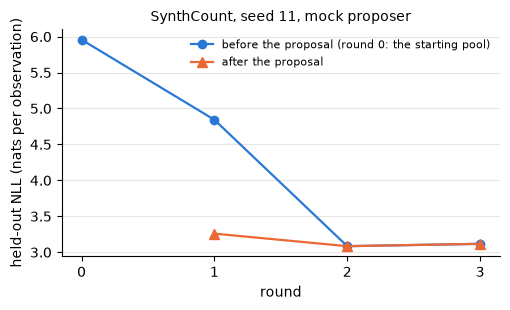

In [21]:
import matplotlib.pyplot as plt

nll = pd.DataFrame([{"round": row["round"], "phase": row["phase"], "nll": row["bma"]["nll"]} for row in scores])
before_series = nll[nll.phase.isin(["initial", "before_proposal"])]
after_series = nll[nll.phase == "after_proposal"]
fig, ax = plt.subplots(figsize=(5.2, 3.2), dpi=100)
ax.plot(before_series["round"], before_series["nll"], marker="o", markersize=6, linewidth=1.6,
        color="#2a78d6", label="before the proposal (round 0: the starting pool)")
ax.plot(after_series["round"], after_series["nll"], marker="^", markersize=7, linewidth=1.6,
        color="#eb6834", label="after the proposal")
ax.set_xlabel("round")
ax.set_ylabel("held-out NLL (nats per observation)")
ax.set_xticks(sorted(nll["round"].unique()))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8)
ax.set_title("SynthCount, seed 11, mock proposer", fontsize=10)
fig.tight_layout()
plt.show()

In rounds 2 and 3 the two points coincide: the new candidates were admitted but received almost
no weight, so the pool's prediction barely changed.

## Next

- [02 · What the LLM sees](02_what_the_llm_sees.ipynb): the belief packet as it is sent, the
  system prompt and the extra paragraphs of multi-candidate requests.
- [03 · EIG decomposition](03_eig_decomposition.ipynb): joint EIG = Model EIG + Parameter EIG,
  and how expected predictive information gain (EPIG) differs.
- [04 · Reading a run folder](04_reading_a_run_folder.ipynb): the records of this run with
  pandas, one score recomputed by hand, and a comparison with a second run.